In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

df = pd.read_csv("emails.csv")

print("Dataset loaded successfully!")
print(df.head())


Dataset loaded successfully!
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]


In [3]:

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum().sum())


Dataset Shape:
(5172, 3002)

Column Names:
Index(['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='object', length=3002)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB

Statistical Description:
               the           to          ect          and          for  \
count  5172.000000  5172.000000  5172.000000  5172.000000  5172.000000   
mean      6.640565     6.188128     5.143852     3.075599     3.124710   
std      11.745009     9.534576    14.101142     6.045970     4.680522   
min       0.000000     0.000000     1.000000     0.000000     0.000000   
25%       0.000000     1.000000     1.000000     0.000000     1.000000   
50%       3.000000     3.000000     1.000000

In [4]:

# Remove unnecessary Email No. column
if 'Email No.' in df.columns:
    df.drop('Email No.', axis=1, inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Separate target column
if 'Prediction' not in df.columns:
    raise ValueError("Prediction column not found!")

# Convert target labels into numeric values
if df['Prediction'].dtype == 'object':
    df['Prediction'] = df['Prediction'].astype(str).str.strip().str.lower()
    df['Prediction'] = df['Prediction'].map({
        'not spam': 0,
        'spam': 1
    })

df['Prediction'] = pd.to_numeric(
    df['Prediction'], errors='coerce'
)

# Remove missing target values
df.dropna(subset=['Prediction'], inplace=True)

# Convert feature columns into numeric values
X = df.drop('Prediction', axis=1)
X = X.apply(pd.to_numeric, errors='coerce')

# Fill missing feature values
X = X.fillna(0)

# Store target variable
y = df['Prediction'].astype(int)

print("Data preprocessing completed!")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)


Data preprocessing completed!
Feature shape: (4631, 3000)
Target shape: (4631,)


Email Classification Count:
Prediction
0    3170
1    1461
Name: count, dtype: int64

Email Classification Percentage:
Prediction
0    68.451738
1    31.548262
Name: proportion, dtype: float64


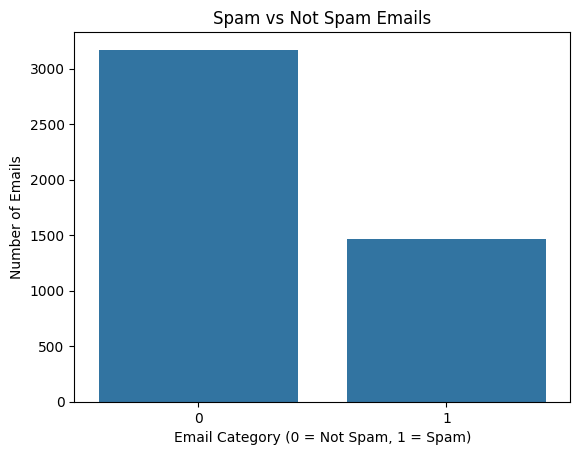

In [5]:

print("Email Classification Count:")
print(y.value_counts())

print("\nEmail Classification Percentage:")
print(y.value_counts(normalize=True) * 100)

sns.countplot(x=y)
plt.title("Spam vs Not Spam Emails")
plt.xlabel("Email Category (0 = Not Spam, 1 = Spam)")
plt.ylabel("Number of Emails")
plt.show()


In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (3241, 3000)
Testing data: (1390, 3000)


In [7]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed!")


Feature scaling completed!


In [8]:

knn = KNeighborsClassifier(n_neighbors=7)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Classification Completed!")


KNN Classification Completed!


In [9]:

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

print("\nKNN Confusion Matrix:")
cm_knn = confusion_matrix(y_test, y_pred_knn)
print(cm_knn)

print("\nKNN Classification Report:")
print(classification_report(y_test, y_pred_knn))


KNN Accuracy: 0.8064748201438849

KNN Confusion Matrix:
[[702 249]
 [ 20 419]]

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.74      0.84       951
           1       0.63      0.95      0.76       439

    accuracy                           0.81      1390
   macro avg       0.80      0.85      0.80      1390
weighted avg       0.86      0.81      0.81      1390



In [10]:

svm_model = SVC(C=1)

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("SVM Classification Completed!")


SVM Classification Completed!


In [11]:

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

print("\nSVM Confusion Matrix:")
cm_svm = confusion_matrix(y_test, y_pred_svm)
print(cm_svm)

print("\nSVM Classification Report:")
print(classification_report(y_test, y_pred_svm))


SVM Accuracy: 0.920863309352518

SVM Confusion Matrix:
[[946   5]
 [105 334]]

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.95       951
           1       0.99      0.76      0.86       439

    accuracy                           0.92      1390
   macro avg       0.94      0.88      0.90      1390
weighted avg       0.93      0.92      0.92      1390



In [12]:

results = pd.DataFrame({
    'Algorithm': ['KNN', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Precision': [
        precision_score(y_test, y_pred_knn, zero_division=0),
        precision_score(y_test, y_pred_svm, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_knn, zero_division=0),
        recall_score(y_test, y_pred_svm, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_knn, zero_division=0),
        f1_score(y_test, y_pred_svm, zero_division=0)
    ]
})

print("Model Performance Comparison:")
print(results)


Model Performance Comparison:
  Algorithm  Accuracy  Precision    Recall  F1 Score
0       KNN  0.806475   0.627246  0.954442  0.757001
1       SVM  0.920863   0.985251  0.760820  0.858612


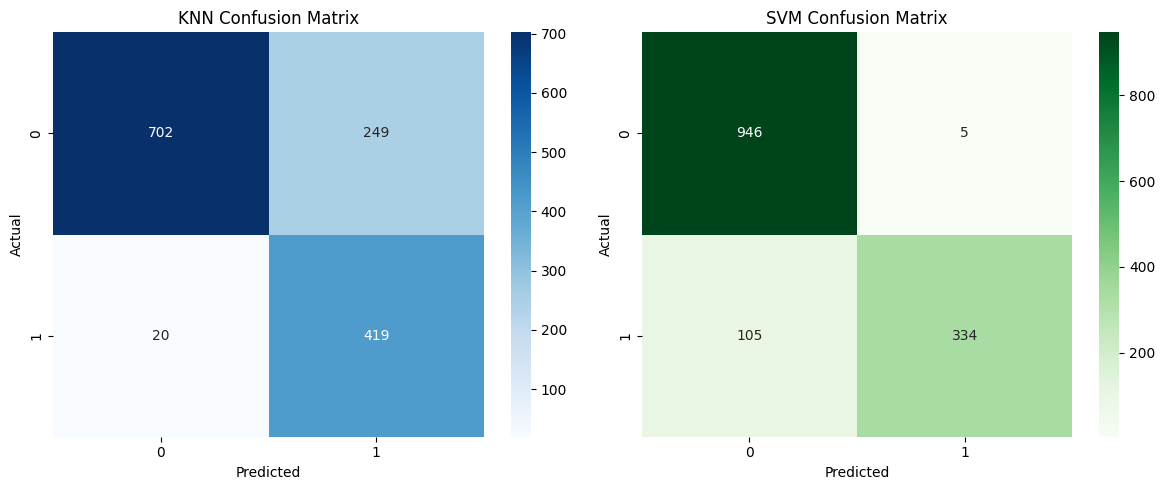

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)
axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


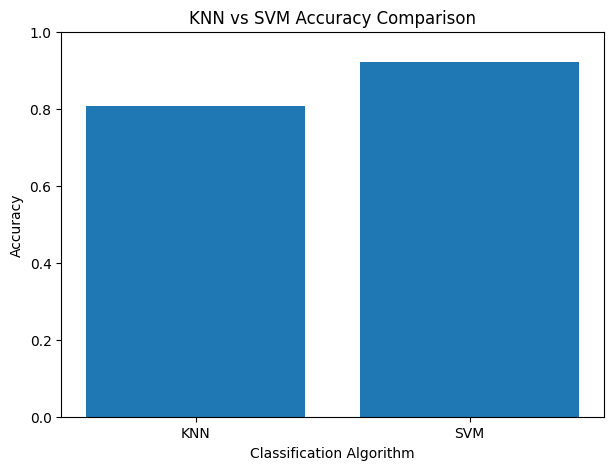

In [14]:

plt.figure(figsize=(7, 5))

plt.bar(
    results['Algorithm'],
    results['Accuracy']
)

plt.title("KNN vs SVM Accuracy Comparison")
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()
